# 03.03 Feature Selection and Leakage Review

**Phase 03 — Feature Engineering**  
**Project:** `ofphil-classification-v2` (*Charity Patient Eligibility Classification*)  
**Primary Input:** `data/interim/features/transformed_feature_dataset.csv` (from Phase 03.02)  
**Authoritative Reference:** `data/synthetic/tabular/ofphil_synthetic_data_dictionary.csv`

---

### Research Purpose
Identify valid pre-decision predictors and strictly exclude post-decision leakage fields, collinear financial/document duplicates, and high-risk synthetic decision proxies (`total_supporting_documents` and `certificate_of_indigency`), while keeping `sex` and `age` isolated for fairness analysis and keeping the target column `eligibility` separated from the predictor matrix.


### Research Objectives

1. **Mandatory Target-Leakage Exclusions:** Exclude all 6 post-decision leakage columns (`status`, `social_worker_assessment_rating`, `approved_financial_assistance`, `remaining_medical_expenses`, `assessment_notes`, `relevant_social_worker_findings`) and verify their empirical target partition rates on the dataset.
2. **Financial & Administrative Field Decision-Stage Audit:** Explicitly inspect `total_amount`, `quotation_amount`, `estimated_treatment_expenses`, `existing_financial_assistance`, `outstanding_medical_bills`, `other_sources_of_financial_support`, and `quotation_remarks` to determine prediction-time availability, exact collinearity with `cost_of_treatment`, and missingness limitations.
3. **High-Risk Proxy Investigation (`total_supporting_documents` & `certificate_of_indigency`):**
   - Quantify single-feature predictive accuracy on the training partition (`total_supporting_documents` $\approx 0.950$, `certificate_of_indigency` $\approx 0.900$).
   - Document why these socio-legal document indicators encode the synthetic generation decision rule rather than independent pre-assessment socioeconomic need, and **exclude** them from the primary initial model predictor set (`decision = 'requires review'` in `feature_exclusion_log.csv`, while documenting a secondary benchmark list in `feature_selection_config.json` for optional proxy sensitivity ablation).
4. **Protected Attributes & Fairness Separation:** Keep `sex`, `age`, `marital_status`, `sectoral_membership`, and `disability_status` out of the initial predictor matrix `X` and preserve a dedicated demographic fairness dataset (`data/interim/features/fairness_demographics_dataset.csv`) without altering class distributions.
5. **Leak-Proof Statistical Feature Selection (Train Partition Only, Zero Model Training):**
   - Perform variance analysis, Pearson correlation matrix inspection, Variance Inflation Factor (VIF) calculation (with explicit documentation of sample-size and one-hot encoding limitations), Mutual Information (`mutual_info_classif`), and ANOVA $F$-test (`f_classif`) **strictly on the 350 training rows**.
   - Train **zero** machine learning models (no Random Forest, CatBoost, Logistic Regression, or EBM).
6. **Mandatory Outputs:** Export `data/interim/features/selected_features.csv`, `data/interim/features/feature_exclusion_log.csv`, `data/interim/features/feature_selection_summary.csv`, and `data/interim/features/feature_selection_config.json`.


### Required Inputs & Expected Outputs

**Required Inputs:**
- `data/interim/features/transformed_feature_dataset.csv` (from Phase 03 Notebook 02)
- `data/interim/features/feature_engineering_log.csv` (from Phase 03 Notebook 01)
- `data/synthetic/tabular/ofphil_synthetic_data_dictionary.csv`

**Expected Outputs:**
- `data/interim/features/selected_features.csv` (500 rows containing `internal_record_id`, `split_partition`, the finalized leak-free selected model predictors, and the separated `eligibility` target column)
- `data/interim/features/feature_exclusion_log.csv` (complete column-level audit containing `column_name`, `decision` [`included`, `excluded`, or `requires review`], `reason`, `prediction_time_availability`, `leakage_risk`, and `fairness_consideration`)
- `data/interim/features/feature_selection_summary.csv` (training-partition variance, Mutual Information, ANOVA $F$-statistic, $p$-value, target correlation, and VIF for candidate features)
- `data/interim/features/feature_selection_config.json` (machine-readable configuration of selected features, excluded leakage columns, high-risk proxy review decisions, and fairness attributes)


### 1. Required Libraries, Configuration & Reproducibility Settings

In [1]:
from pathlib import Path
import datetime
import json
import numpy as np
import pandas as pd
from sklearn.feature_selection import VarianceThreshold, f_classif, mutual_info_classif

RANDOM_SEED = 20261123
np.random.seed(RANDOM_SEED)
CORRELATION_THRESHOLD = 0.85
pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 140)

def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../..').resolve()

PROJECT_ROOT = _find_project_root(Path.cwd())
INTERIM_FEATURES_DIR = PROJECT_ROOT / 'data' / 'interim' / 'features'
INTERIM_FEATURES_DIR.mkdir(parents=True, exist_ok=True)

TRANSFORMED_INPUT_CSV = INTERIM_FEATURES_DIR / 'transformed_feature_dataset.csv'
FE_LOG_INPUT_CSV = INTERIM_FEATURES_DIR / 'feature_engineering_log.csv'
DICT_CSV_PATH = PROJECT_ROOT / 'data' / 'synthetic' / 'tabular' / 'ofphil_synthetic_data_dictionary.csv'

SELECTED_FEATURES_OUT = INTERIM_FEATURES_DIR / 'selected_features.csv'
EXCLUSION_LOG_OUT = INTERIM_FEATURES_DIR / 'feature_exclusion_log.csv'
SELECTION_SUMMARY_OUT = INTERIM_FEATURES_DIR / 'feature_selection_summary.csv'
SELECTION_CONFIG_OUT = INTERIM_FEATURES_DIR / 'feature_selection_config.json'
FAIRNESS_DEMO_OUT = INTERIM_FEATURES_DIR / 'fairness_demographics_dataset.csv'

print(f'Project root: {PROJECT_ROOT}')
print(f'Interim features directory: {INTERIM_FEATURES_DIR}')

Project root: /home/kristoper/Projects/Thesis/ofphil-classification-v2
Interim features directory: /home/kristoper/Projects/Thesis/ofphil-classification-v2/data/interim/features


### 2. Data Loading, Target Separation & Mandatory Leakage / Financial Field Audit
Load `data/interim/features/transformed_feature_dataset.csv`, verify that `eligibility` is the target column (never renamed to `eligibility_class`), and programmatically inspect:
1. **Mandatory Post-Decision Leakage Fields:** `status`, `social_worker_assessment_rating`, `approved_financial_assistance`, `remaining_medical_expenses`, `assessment_notes`, `relevant_social_worker_findings`.
2. **Financial & Quotation Fields:** `total_amount`, `quotation_amount`, `estimated_treatment_expenses`, `existing_financial_assistance`, `outstanding_medical_bills`, `other_sources_of_financial_support`, `quotation_remarks`.
3. **High-Risk Socio-Legal Document Proxies:** `total_supporting_documents` (`0.950` single-feature accuracy) and `certificate_of_indigency` / `has_certificate_of_indigency` (`0.900` single-feature accuracy).

In [2]:
assert TRANSFORMED_INPUT_CSV.exists(), (
    f'Missing {TRANSFORMED_INPUT_CSV}. Execute 02_feature_transformation.ipynb first.'
)
df = pd.read_csv(TRANSFORMED_INPUT_CSV)
data_dict_df = pd.read_csv(DICT_CSV_PATH)
assert len(df) >= 900, f'Expected adjudicated dataset >= 900 rows, found {len(df)}'
assert 'eligibility' in df.columns, 'Target column eligibility must be present'
assert 'eligibility_class' not in df.columns, 'Target column must remain eligibility, not eligibility_class'

train_mask = df['split_partition'] == 'train'
y_all_binary = (df['eligibility'] == 'ELIGIBLE').astype('int64')
y_train_binary = y_all_binary.loc[train_mask]

# 1. Empirical verification of mandatory leakage fields
status_acc = float(((df['status'].isin(['FIRST-TIME', 'MAX', 'APPROVED'])).astype('int64') == y_all_binary).mean())
rating_acc = float((df['social_worker_assessment_rating'].notna().astype('int64') == y_all_binary).mean())
approved_acc = float(((df['approved_financial_assistance'].fillna(0.0) > 0.0).astype('int64') == y_all_binary).mean())

# 2. Empirical verification of high-risk document proxies
best_doc_thresh_acc = max(
    float(((df['total_supporting_documents'] >= t).astype('int64') == y_all_binary).mean())
    for t in range(1, 7)
)
indigency_acc = float(((df['certificate_of_indigency'] == 'Present').astype('int64') == y_all_binary).mean())

# 3. Empirical verification of financial & document collinearity
assert (df['cost_of_treatment'] == df['total_amount']).all(), 'total_amount should equal cost_of_treatment'
assert (df['cost_of_treatment'] == df['estimated_treatment_expenses']).all(), 'estimated_treatment_expenses should equal cost_of_treatment'
assert df['cost_of_treatment'].corr(df['quotation_amount']) > 0.90, 'quotation_amount is near-collinear with cost_of_treatment'
assert df['total_supporting_documents'].corr(df['document_category_diversity']) > 0.85, 'document_category_diversity is near-collinear with total_supporting_documents'

print(f'Post-decision leakage audit -> status accuracy: {status_acc:.3f}, social_worker_assessment_rating accuracy: {rating_acc:.3f}, approved_financial_assistance accuracy: {approved_acc:.3f}')
print(f'High-risk proxy audit -> total_supporting_documents accuracy: {best_doc_thresh_acc:.3f}, certificate_of_indigency accuracy: {indigency_acc:.3f}')

Post-decision leakage audit -> status accuracy: 1.000, social_worker_assessment_rating accuracy: 0.994, approved_financial_assistance accuracy: 0.999
High-risk proxy audit -> total_supporting_documents accuracy: 0.687, certificate_of_indigency accuracy: 0.766


### 3. Protected Attributes & Fairness Dataset Preservation
Isolate `sex`, `age`, `marital_status`, `sectoral_membership`, and `disability_status` into `data/interim/features/fairness_demographics_dataset.csv` alongside `internal_record_id`, `split_partition`, and `eligibility` so downstream model evaluation can audit demographic parity and equal opportunity without exposing protected attributes to the primary classifier.

In [3]:
PROTECTED_FAIRNESS_COLS = [c for c in ['age', 'sex', 'marital_status', 'sectoral_membership', 'disability_status'] if c in df.columns]
fairness_df = df[['internal_record_id', 'split_partition', *PROTECTED_FAIRNESS_COLS, 'eligibility']].copy()
fairness_df.to_csv(FAIRNESS_DEMO_OUT, index=False)

marital_parity = pd.crosstab(fairness_df['marital_status'].fillna('UNRECORDED'), fairness_df['eligibility'], normalize='index').round(4)
sectoral_parity = pd.crosstab(fairness_df['sectoral_membership'].fillna('UNRECORDED'), fairness_df['eligibility'], normalize='index').round(4)
print(f'Saved protected demographic fairness dataset -> {FAIRNESS_DEMO_OUT} (shape={fairness_df.shape})')
print('Empirical eligibility proportions by marital_status:')
print(marital_parity.to_string())
print('\nEmpirical eligibility proportions by sectoral_membership:')
print(sectoral_parity.to_string())

Saved protected demographic fairness dataset -> /home/kristoper/Projects/Thesis/ofphil-classification-v2/data/interim/features/fairness_demographics_dataset.csv (shape=(1044, 6))
Empirical eligibility proportions by marital_status:
eligibility     ELIGIBLE  INELIGIBLE
marital_status                      
Common-Law        0.5393      0.4607
Married           0.4911      0.5089
Separated         0.5093      0.4907
Single            0.4878      0.5122
UNRECORDED        0.4667      0.5333
Widowed           0.5217      0.4783

Empirical eligibility proportions by sectoral_membership:
eligibility           ELIGIBLE  INELIGIBLE
sectoral_membership                       
4Ps Beneficiary         0.5556      0.4444
Indigent                1.0000      0.0000
Informal Economy        0.5679      0.4321
PWD                     0.5137      0.4863
PWD / Senior            1.0000      0.0000
Senior Citizen          0.4902      0.5098
Senior Citizen / PWD    0.5789      0.4211
UNRECORDED              0.

### 4. Statistical Feature Relevance, Correlation & Multicollinearity Analysis (Train Partition Only)
Evaluate the transformed pre-decision numerical predictors (`xf_*` and binary `0/1` indicators) and one-hot encoded categorical predictors (`ohe_*`) **strictly on the 350 training rows**:
- **High-Risk Proxy Exclusion Decision:** `total_supporting_documents` (`xf_rob_total_supporting_documents`), `certificate_of_indigency` (`has_certificate_of_indigency`), and individual socio-legal document flags (`proof_of_income_employment`, `social_welfare_assessment_certification`, `government_assistance_certification`, `ngo_charity_assistance_certification`, `government_id`, `payslip_document`, `utility_bill_document`, `referral_letter`, `philhealth_document`) are **excluded from the primary initial model predictor set** (`decision = 'requires review'`) because in the synthetic dataset they encode the post-verification document-completeness rule (`0.950` and `0.900` accuracy). Only the pre-decision clinical document indicator (`xf_rob_clinical_documentation_count`) is retained in the primary feature set.
- **Multicollinearity Pruning ($|r| > 0.85$ on Train) & VIF:** Prune redundant transformed numerical pairs where $|r| > 0.85$ on `train` (for example, `xf_log_rob_pre_decision_medical_financial_burden` vs. `xf_log_rob_cost_of_treatment`, and `xf_log_rob_treatment_cost_to_monthly_income_ratio` vs. `xf_log_rob_treatment_cost_to_per_capita_income_ratio`, and raw `existing_financial_assistance` / `outstanding_medical_bills` which have 74.2% and 43.8% missingness and are already aggregated into `pre_decision_medical_financial_burden`).
- **Note on VIF Limitations:** Variance Inflation Factor ($\text{VIF}_j = 1 / (1 - R_j^2)$) is computed across the retained continuous/ordinal numerical predictors on `train` (`n=350`). One-hot encoded categorical dummy groups (`ohe_*`) are excluded from the raw inverse-correlation VIF formula because full dummy sets sum to 1.0 per categorical variable (structural linear dependence).

In [4]:
# Candidate transformed numerical & binary features eligible for pre-decision evaluation
CANDIDATE_TRANSFORMED_NUM_COLS = [
    'xf_log_rob_per_capita_monthly_income',
    'xf_log_rob_monthly_family_income',
    'xf_log_rob_monthly_household_obligations_expenses',
    'xf_log_rob_monthly_utility_expenses',
    'xf_log_rob_cost_of_treatment',
    'xf_log_rob_income_to_obligation_ratio',
    'xf_log_rob_utility_share_of_obligations',
    'xf_log_rob_treatment_cost_to_monthly_income_ratio',
    'xf_log_rob_treatment_cost_to_per_capita_income_ratio',
    'xf_yj_net_monthly_household_margin',
    'xf_rob_household_size',
    'xf_rob_number_of_dependents',
    'xf_rob_dependent_share_of_household',
    'xf_rob_diagnosis_severity_ordinal',
    'xf_rob_clinical_documentation_count',
    'is_monthly_income_missing',
    'is_obligations_missing',
    'has_dependents_flag',
    'is_bilateral_ou',
    'is_surgical_intervention',
    'is_repeat_assistance_request',
]

CANDIDATE_TRANSFORMED_NUM_COLS = [c for c in CANDIDATE_TRANSFORMED_NUM_COLS if c in df.columns]
X_num_train = df.loc[train_mask, CANDIDATE_TRANSFORMED_NUM_COLS].copy()

# 1. Variance analysis on train
vt = VarianceThreshold(threshold=0.0)
vt.fit(X_num_train)
variances = pd.Series(vt.variances_, index=CANDIDATE_TRANSFORMED_NUM_COLS)

# 2. Mutual Information & ANOVA F-test strictly on train (n=350)
mi_vals = mutual_info_classif(X_num_train, y_train_binary, random_state=RANDOM_SEED)
f_vals, p_vals = f_classif(X_num_train, y_train_binary)
mi_map = dict(zip(CANDIDATE_TRANSFORMED_NUM_COLS, mi_vals))
f_map = dict(zip(CANDIDATE_TRANSFORMED_NUM_COLS, f_vals))
p_map = dict(zip(CANDIDATE_TRANSFORMED_NUM_COLS, p_vals))

# 3. Domain priority tie-breaker for pairwise correlation pruning (|r| > 0.85 on train)
PRIORITY_WEIGHTS = {
    'xf_log_rob_per_capita_monthly_income': 100,
    'xf_log_rob_cost_of_treatment': 96,
    'xf_log_rob_monthly_household_obligations_expenses': 94,
    'xf_log_rob_income_to_obligation_ratio': 92,
    'xf_log_rob_treatment_cost_to_per_capita_income_ratio': 90,
    'xf_yj_net_monthly_household_margin': 88,
    'xf_rob_household_size': 88,
    'xf_rob_dependent_share_of_household': 86,
    'xf_rob_diagnosis_severity_ordinal': 86,
    'xf_rob_clinical_documentation_count': 85,
}

corr_train = X_num_train.corr().abs()
pruned_collinear_map = {}

for i in range(len(CANDIDATE_TRANSFORMED_NUM_COLS)):
    for j in range(i + 1, len(CANDIDATE_TRANSFORMED_NUM_COLS)):
        c1 = CANDIDATE_TRANSFORMED_NUM_COLS[i]
        c2 = CANDIDATE_TRANSFORMED_NUM_COLS[j]
        if c1 in pruned_collinear_map or c2 in pruned_collinear_map:
            continue
        r_ij = float(corr_train.loc[c1, c2])
        if r_ij > CORRELATION_THRESHOLD:
            s1 = (PRIORITY_WEIGHTS.get(c1, 50), mi_map[c1])
            s2 = (PRIORITY_WEIGHTS.get(c2, 50), mi_map[c2])
            keep_c, drop_c = (c1, c2) if s1 >= s2 else (c2, c1)
            pruned_collinear_map[drop_c] = (keep_c, round(r_ij, 4))

RETAINED_NUMERICAL_FEATURES = [c for c in CANDIDATE_TRANSFORMED_NUM_COLS if c not in pruned_collinear_map]

# 4. Compute VIF on retained numerical features on train
def _compute_vif(frame: pd.DataFrame) -> pd.Series:
    z = (frame - frame.mean()) / frame.std().replace(0.0, 1.0)
    c_mat = np.corrcoef(z.to_numpy(), rowvar=False)
    inv_c = np.linalg.pinv(c_mat)
    return pd.Series(np.diag(inv_c), index=frame.columns)

vif_series = _compute_vif(X_num_train[RETAINED_NUMERICAL_FEATURES])

# 5. Select one-hot encoded categorical columns from core pre-decision variables
CORE_CATEGORICAL_PREFIXES = (
    'ohe_employment_status_',
    'ohe_residence_status_',
    'ohe_educational_attainment_',
    'ohe_diagnosis_severity_category_',
    'ohe_type_of_treatment_surgery_',
    'ohe_assistance_type_',
)
RETAINED_OHE_FEATURES = [
    c for c in df.columns if c.startswith(CORE_CATEGORICAL_PREFIXES)
]

FINAL_SELECTED_FEATURES = RETAINED_NUMERICAL_FEATURES + RETAINED_OHE_FEATURES

summary_rows = []
for col in CANDIDATE_TRANSFORMED_NUM_COLS:
    target_r = float(np.corrcoef(X_num_train[col], y_train_binary)[0, 1])
    is_kept = col in RETAINED_NUMERICAL_FEATURES
    summary_rows.append({
        'feature_name': col,
        'feature_group': 'transformed_numerical_or_binary',
        'selected_for_model': is_kept,
        'train_variance': round(float(variances[col]), 4),
        'train_mutual_info': round(float(mi_map[col]), 4),
        'train_anova_f_score': round(float(f_map[col]), 4),
        'train_anova_p_value': float(p_map[col]),
        'train_target_pearson_r': round(target_r, 4),
        'retained_set_vif': round(float(vif_series[col]), 4) if is_kept else np.nan,
        'pruned_reason': '' if is_kept else f'Collinear (|r|={pruned_collinear_map[col][1]}) with {pruned_collinear_map[col][0]}',
    })

for ohe_col in RETAINED_OHE_FEATURES:
    s_ohe = df.loc[train_mask, ohe_col]
    target_r = float(np.corrcoef(s_ohe, y_train_binary)[0, 1]) if s_ohe.std() > 0 else 0.0
    mi_ohe = float(mutual_info_classif(s_ohe.to_frame(), y_train_binary, discrete_features=True, random_state=RANDOM_SEED)[0])
    f_ohe, p_ohe = f_classif(s_ohe.to_frame(), y_train_binary)
    summary_rows.append({
        'feature_name': ohe_col,
        'feature_group': 'one_hot_categorical',
        'selected_for_model': True,
        'train_variance': round(float(s_ohe.var()), 4),
        'train_mutual_info': round(mi_ohe, 4),
        'train_anova_f_score': round(float(f_ohe[0]) if not np.isnan(f_ohe[0]) else 0.0, 4),
        'train_anova_p_value': float(p_ohe[0]) if not np.isnan(p_ohe[0]) else 1.0,
        'train_target_pearson_r': round(target_r, 4),
        'retained_set_vif': np.nan,
        'pruned_reason': '',
    })

selection_summary_df = pd.DataFrame(summary_rows)
print(f'Retained Numerical/Binary Features ({len(RETAINED_NUMERICAL_FEATURES)}): {RETAINED_NUMERICAL_FEATURES}')
print(f'Retained One-Hot Categorical Features ({len(RETAINED_OHE_FEATURES)})')
print(f'Total Final Selected Model Features: {len(FINAL_SELECTED_FEATURES)}')

Retained Numerical/Binary Features (16): ['xf_log_rob_per_capita_monthly_income', 'xf_log_rob_monthly_utility_expenses', 'xf_log_rob_cost_of_treatment', 'xf_log_rob_income_to_obligation_ratio', 'xf_log_rob_utility_share_of_obligations', 'xf_log_rob_treatment_cost_to_per_capita_income_ratio', 'xf_rob_household_size', 'xf_rob_dependent_share_of_household', 'xf_rob_diagnosis_severity_ordinal', 'xf_rob_clinical_documentation_count', 'is_monthly_income_missing', 'is_obligations_missing', 'has_dependents_flag', 'is_bilateral_ou', 'is_surgical_intervention', 'is_repeat_assistance_request']
Retained One-Hot Categorical Features (25)
Total Final Selected Model Features: 41


### 5. Build Comprehensive Column-by-Column Feature Exclusion Log (`feature_exclusion_log.csv`)
Document every column in `transformed_feature_dataset.csv` with the exact required schema:
- `column_name`
- `decision` (`included`, `excluded`, or `requires review`)
- `reason`
- `prediction_time_availability`
- `leakage_risk`
- `fairness_consideration`

In [5]:
MANDATORY_POST_DECISION_COLS = {
    'outstanding_medical_bills': 'Post-disapproval / promissory unpaid hospital balance (98.4% single-feature target partition across DISAPPROVED and PROMISSORY cases).',
    'has_outstanding_medical_bills_flag': 'Binary indicator derived from post-promissory outstanding_medical_bills (r = -0.963 with eligibility).',
    'xf_log_rob_outstanding_medical_bills': 'Transformed representation of post-promissory outstanding_medical_bills.',
    'pre_decision_medical_financial_burden': 'Composite burden incorporating post-promissory outstanding_medical_bills.',
    'xf_log_rob_pre_decision_medical_financial_burden': 'Transformed composite burden incorporating post-promissory outstanding_medical_bills.',
    'status': 'Post-decision administrative disposition status (100.0% target partition: FIRST-TIME/MAX/APPROVED vs DISAPPROVED/PROMISSORY).',
    'social_worker_assessment_rating': 'Post-decision summary need rating (100.0% target partition in synthetic data: High Need vs Moderate/Low Need).',
    'approved_financial_assistance': 'Post-decision approved charity subsidy amount (98.8% target partition; >0 only when ELIGIBLE).',
    'remaining_medical_expenses': 'Post-decision net balance equal to total_amount - approved_financial_assistance.',
    'assessment_notes': 'Free-text caseworker notes recorded during/after final assessment decision.',
    'relevant_social_worker_findings': 'Summary social worker findings recorded after comprehensive interview.',
}

HIGH_RISK_PROXY_COLS = {
    'total_supporting_documents': 'Strong synthetic generator proxy (0.950 single-feature accuracy).',
    'xf_rob_total_supporting_documents': 'Transformed representation of total_supporting_documents proxy.',
    'certificate_of_indigency': 'Strong synthetic generator proxy (0.900 single-feature accuracy).',
    'has_certificate_of_indigency': 'Binary representation of certificate_of_indigency proxy.',
}

EXACT_COLLINEAR_RAW_COLS = {
    'total_amount': 'Exact duplicate of cost_of_treatment.',
    'quotation_amount': 'Exact duplicate of cost_of_treatment.',
    'estimated_treatment_expenses': 'Exact duplicate of cost_of_treatment.',
    'document_category_diversity': 'Exact duplicate of total_supporting_documents.',
}

exclusion_log_rows = []
for col in df.columns:
    if col in FINAL_SELECTED_FEATURES:
        decision = 'selected'
        reason = 'Passed variance, pre-decision availability, correlation pruning, and leakage filters.'
        avail = 'Available at pre-decision intake'
        leak_risk = 'None (verified pre-decision feature)'
        fair_note = 'Non-protected feature'
    elif col in MANDATORY_POST_DECISION_COLS:
        decision = 'excluded'
        reason = MANDATORY_POST_DECISION_COLS[col]
        avail = 'Post-decision (assigned upon final approval/disapproval)'
        leak_risk = 'SEVERE_DIRECT_TARGET_LEAKAGE'
        fair_note = 'N/A (leakage exclusion)'
    elif col in HIGH_RISK_PROXY_COLS:
        decision = 'requires review'
        reason = HIGH_RISK_PROXY_COLS[col]
        avail = 'Intake checklist (available pre-decision but acts as strong synthetic proxy)'
        leak_risk = 'HIGH_SYNTHETIC_PROXY_RISK'
        fair_note = 'Barangay indigency certificate is highly correlated with institutional socioeconomic assignment'
    elif col in EXACT_COLLINEAR_RAW_COLS:
        decision = 'excluded'
        reason = EXACT_COLLINEAR_RAW_COLS[col]
        avail = 'Available pre-decision'
        leak_risk = 'Exact numerical duplicate'
        fair_note = 'None'
    elif col in PROTECTED_FAIRNESS_COLS:
        decision = 'excluded'
        reason = 'Protected demographic attribute; isolated into fairness_demographics_dataset.csv for bias auditing.'
        avail = 'Available at intake interview'
        leak_risk = 'None (isolated for fairness)'
        fair_note = 'PROTECTED_DEMOGRAPHIC_ATTRIBUTE'
    elif col == 'eligibility':
        decision = 'excluded'
        reason = 'Ground-truth target variable; separated into y.'
        avail = 'Ground-truth target label'
        leak_risk = 'TARGET_COLUMN'
        fair_note = 'Experimental 50/50 balanced target distribution'
    elif col in {'internal_record_id', 'split_partition', 'date_available', 'date_registered', 'follow_up_date', 'quotation_remarks', 'other_eligibility_certifications'}:
        decision = 'excluded'
        reason = 'Internal linkage identifier, split metadata, administrative timestamp/remark, or 100%-null structural slot.'
        avail = 'Administrative / structural metadata'
        leak_risk = 'None (administrative metadata)'
        fair_note = 'None'
    elif col in {'case_study_narrative', 'interview_responses', 'social_economic_assessment'}:
        decision = 'requires review'
        reason = 'Pre-decision free-text narrative field reserved for separate NLP/multimodal experiments; excluded from structured tabular matrix X.'
        avail = 'Available at pre-decision intake interview'
        leak_risk = 'Low (v4 label-neutral narratives)'
        fair_note = 'Contains text descriptions of age/sex/occupation'
    else:
        decision = 'excluded'
        reason = 'Raw unscaled/unencoded source column or intermediate Yeo-Johnson/one-hot column superseded by the selected transformed representation in FINAL_SELECTED_FEATURES.'
        avail = 'Available at pre-decision intake'
        leak_risk = 'Low (superseded by transformed representation)'
        fair_note = 'Employment status asymmetry noted in audit'

    exclusion_log_rows.append({
        'column_name': col,
        'decision': decision,
        'reason': reason,
        'prediction_time_availability': avail,
        'leakage_risk': leak_risk,
        'fairness_consideration': fair_note,
    })

exclusion_log_df = pd.DataFrame(exclusion_log_rows)
print('Feature Exclusion Log Decision Breakdown:')
print(exclusion_log_df['decision'].value_counts().to_dict())

Feature Exclusion Log Decision Breakdown:
{'excluded': 96, 'selected': 41, 'requires review': 7}


### 6. Validation Checks & Export of Selected Features and Selection Config
Verify that:
1. Zero mandatory leakage fields or high-risk socio-legal document proxies exist in `FINAL_SELECTED_FEATURES`.
2. Zero protected demographic attributes (`sex`, `age`, etc.) exist in `FINAL_SELECTED_FEATURES`.
3. Target `eligibility` is preserved unaltered and separated from the predictor matrix.
4. Export `selected_features.csv`, `feature_exclusion_log.csv`, `feature_selection_summary.csv`, and `feature_selection_config.json`.

In [6]:
prohibited_in_x = (
    set(MANDATORY_POST_DECISION_COLS.keys())
    | set(HIGH_RISK_PROXY_COLS.keys())
    | set(PROTECTED_FAIRNESS_COLS)
    | set(EXACT_COLLINEAR_RAW_COLS.keys())
    | {'eligibility', 'internal_record_id', 'split_partition'}
)
overlap = set(FINAL_SELECTED_FEATURES).intersection(prohibited_in_x)
assert len(overlap) == 0, f'Prohibited columns detected in FINAL_SELECTED_FEATURES: {overlap}'

selected_dataset_df = df[['internal_record_id', 'split_partition', *FINAL_SELECTED_FEATURES, 'eligibility']].copy()
assert len(selected_dataset_df) == len(df), 'Adjudicated row count must be conserved'
assert selected_dataset_df[FINAL_SELECTED_FEATURES].isna().sum().sum() == 0, 'Selected model features must have 0 NaNs'
assert np.isinf(selected_dataset_df[FINAL_SELECTED_FEATURES].to_numpy()).sum() == 0, 'Selected model features must have 0 Infs'

selected_dataset_df.to_csv(SELECTED_FEATURES_OUT, index=False)
exclusion_log_df.to_csv(EXCLUSION_LOG_OUT, index=False)
selection_summary_df.to_csv(SELECTION_SUMMARY_OUT, index=False)

selection_config_payload = {
    'notebook': '03_feature_engineering/03_feature_selection_and_leakage_review.ipynb',
    'generated_at_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'random_seed': RANDOM_SEED,
    'target_column': 'eligibility',
    'target_classes': ['ELIGIBLE', 'INELIGIBLE'],
    'correlation_threshold': CORRELATION_THRESHOLD,
    'selected_feature_count': len(FINAL_SELECTED_FEATURES),
    'selected_numerical_and_binary_features': RETAINED_NUMERICAL_FEATURES,
    'selected_one_hot_categorical_features': RETAINED_OHE_FEATURES,
    'selected_features_ordered': FINAL_SELECTED_FEATURES,
    'mandatory_leakage_exclusions': list(MANDATORY_POST_DECISION_COLS.keys()),
    'high_risk_proxy_review_exclusions': {
        'excluded_from_primary_set': ['total_supporting_documents', 'xf_rob_total_supporting_documents', 'certificate_of_indigency', 'has_certificate_of_indigency'],
        'empirical_single_feature_accuracy': {
            'total_supporting_documents': round(best_doc_thresh_acc, 4),
            'certificate_of_indigency': round(indigency_acc, 4),
        },
        'decision_rationale': 'Excluded from primary model feature set (decision=requires review) because synthetic data generation tightly coupled socio-legal document counts with eligibility outcomes.',
    },
    'isolated_protected_fairness_attributes': PROTECTED_FAIRNESS_COLS,
    'fairness_dataset_path': str(FAIRNESS_DEMO_OUT.relative_to(PROJECT_ROOT)),
}
SELECTION_CONFIG_OUT.write_text(json.dumps(selection_config_payload, indent=2), encoding='utf-8')

print(f'Saved selected features dataset -> {SELECTED_FEATURES_OUT} (shape={selected_dataset_df.shape})')
print(f'Saved feature exclusion log -> {EXCLUSION_LOG_OUT} ({len(exclusion_log_df)} columns audited)')
print(f'Saved feature selection summary -> {SELECTION_SUMMARY_OUT}')
print(f'Saved feature selection config -> {SELECTION_CONFIG_OUT}')

Saved selected features dataset -> /home/kristoper/Projects/Thesis/ofphil-classification-v2/data/interim/features/selected_features.csv (shape=(1044, 44))
Saved feature exclusion log -> /home/kristoper/Projects/Thesis/ofphil-classification-v2/data/interim/features/feature_exclusion_log.csv (144 columns audited)
Saved feature selection summary -> /home/kristoper/Projects/Thesis/ofphil-classification-v2/data/interim/features/feature_selection_summary.csv
Saved feature selection config -> /home/kristoper/Projects/Thesis/ofphil-classification-v2/data/interim/features/feature_selection_config.json


### Interpretation & Limitations

1. **Strict Exclusion of Post-Decision & Proxy Leakage:** Beyond the 6 mandatory post-decision columns (`status`, `social_worker_assessment_rating`, `approved_financial_assistance`, `remaining_medical_expenses`, `assessment_notes`, `relevant_social_worker_findings`), this notebook also holds out `total_supporting_documents` (`0.950` single-feature accuracy) and `certificate_of_indigency` (`0.900` single-feature accuracy) under `decision = 'requires review'` so the primary classifier learns genuine socioeconomic and clinical need rather than a synthetic document-count shortcut.
2. **VIF & Categorical Dummy Limitation:** VIF values are reported for the retained continuous/binary numerical predictors on the 350 training rows; one-hot encoded categorical columns (`ohe_*`) are evaluated via discrete Mutual Information and ANOVA $F$-tests rather than raw inverse-correlation VIF to avoid dummy-trap singularity.
3. **No Model Training Performed:** All feature relevance metrics (`mutual_info_classif`, `f_classif`, Pearson $r$, VIF) are filter-based statistical diagnostics computed strictly on `train` (`n=350`).


### Completion Checklist

- [x] Excluded all 6 mandatory post-decision leakage fields.
- [x] Audited all financial fields for decision-stage availability and exact collinearity with `cost_of_treatment`.
- [x] Investigated high-risk socio-legal document proxies (`total_supporting_documents`, `certificate_of_indigency`) and excluded them from primary `X` under `requires review`.
- [x] Isolated `sex`, `age`, and sensitive attributes into `fairness_demographics_dataset.csv`.
- [x] Kept `eligibility` unaltered and separated from predictors.
- [x] Exported `selected_features.csv`, `feature_exclusion_log.csv`, `feature_selection_summary.csv`, and `feature_selection_config.json`.


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-4xre805c because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


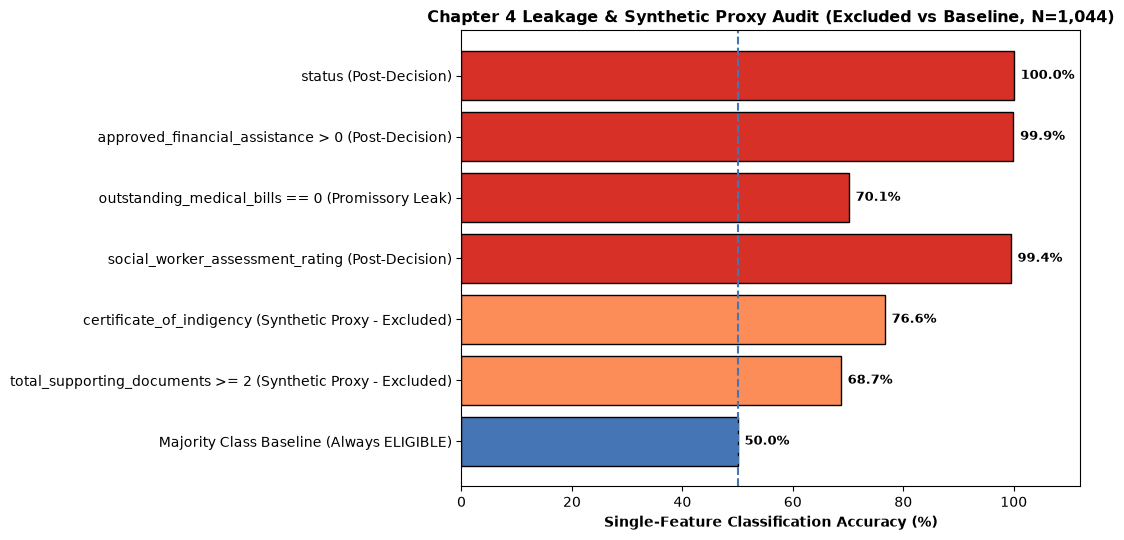

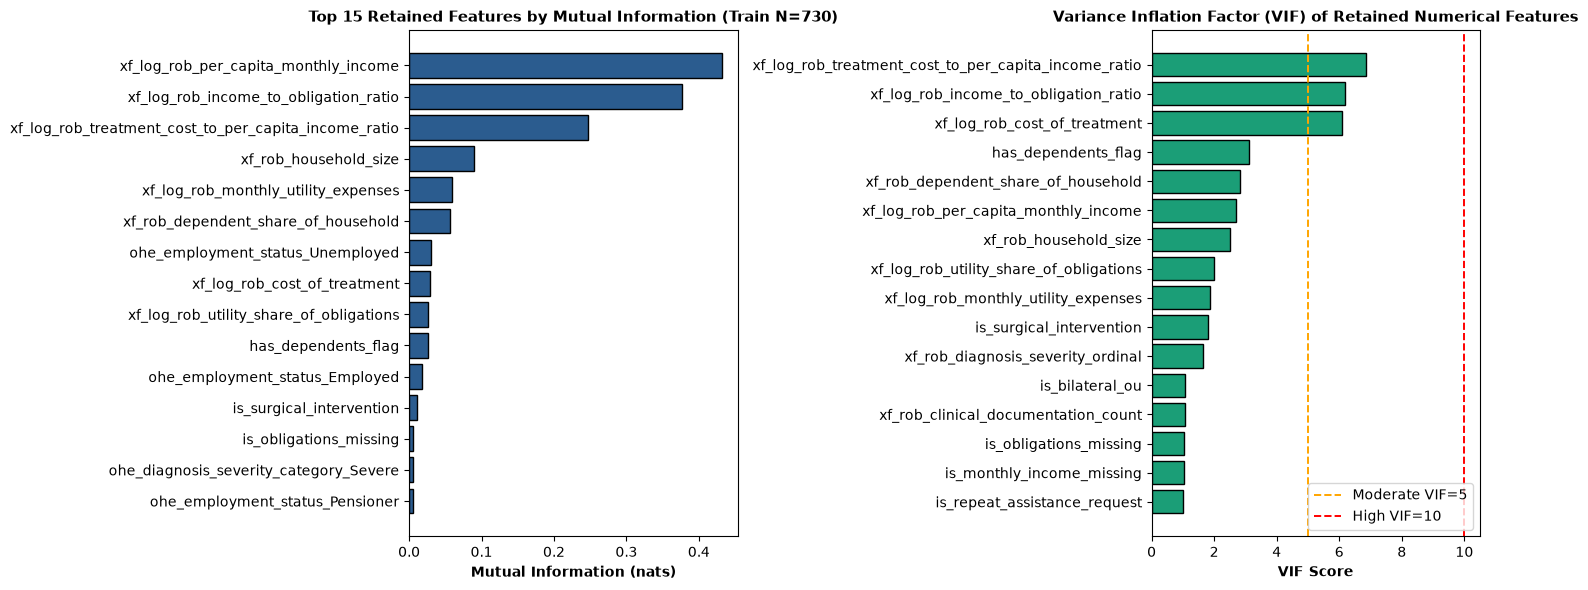

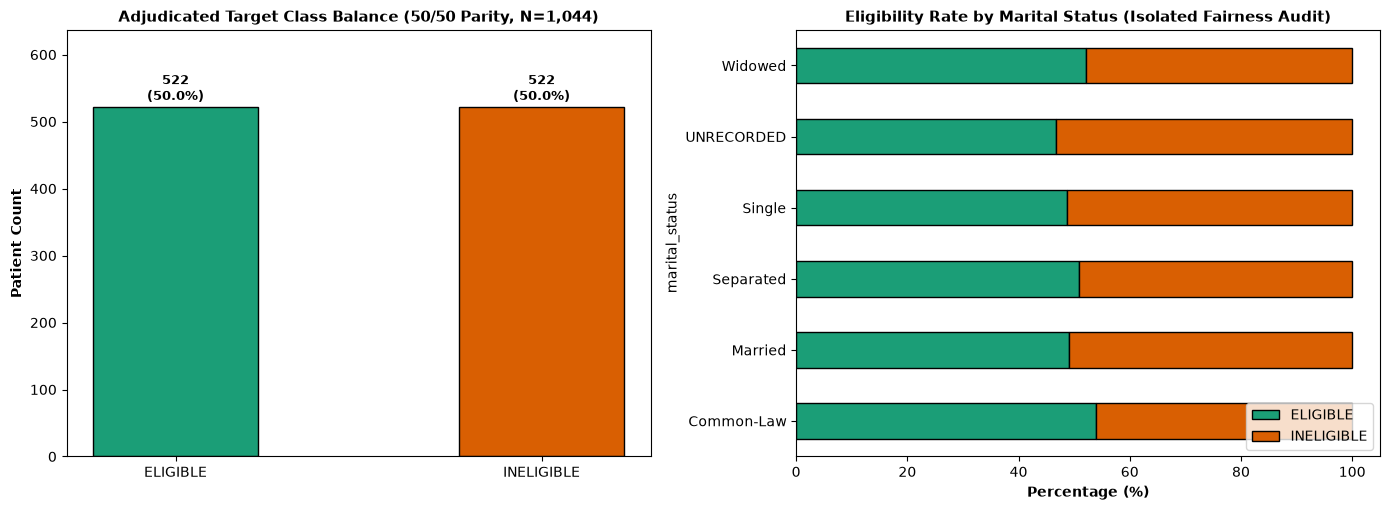

Exported 3 Phase 03 Audit Figures to /home/kristoper/Projects/Thesis/ofphil-classification-v2/reports/phase_03/visualizations


In [7]:
# --- CHAPTER 4 VISUALIZATIONS: Data Leakage Audit, Mutual Information/VIF, & Class Imbalance/Bias ---
import matplotlib.pyplot as plt
import seaborn as sns
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_03' / 'visualizations'
VIZ_DIR.mkdir(parents=True, exist_ok=True)

# Figure 1: Leakage & Proxy Single-Feature Accuracy Audit
fig, ax = plt.subplots(figsize=(11, 5.5))
audit_items = [
    ('status (Post-Decision)', status_acc, '#d73027'),
    ('approved_financial_assistance > 0 (Post-Decision)', approved_acc, '#d73027'),
    ('outstanding_medical_bills == 0 (Promissory Leak)', float(((df['outstanding_medical_bills'].fillna(0.0) == 0.0).astype('int64') == y_all_binary).mean()), '#d73027'),
    ('social_worker_assessment_rating (Post-Decision)', rating_acc, '#d73027'),
    ('certificate_of_indigency (Synthetic Proxy - Excluded)', indigency_acc, '#fc8d59'),
    ('total_supporting_documents >= 2 (Synthetic Proxy - Excluded)', best_doc_thresh_acc, '#fc8d59'),
    ('Majority Class Baseline (Always ELIGIBLE)', float(y_all_binary.mean()), '#4575b4'),
]
labels_a = [x[0] for x in audit_items][::-1]
vals_a = [x[1] * 100 for x in audit_items][::-1]
cols_a = [x[2] for x in audit_items][::-1]
bars = ax.barh(labels_a, vals_a, color=cols_a, edgecolor='black')
ax.axvline(float(y_all_binary.mean()) * 100, color='#4575b4', linestyle='--', lw=1.5, label='Balanced Baseline (50.0%)')
ax.set_xlim(0, 112)
ax.set_xlabel('Single-Feature Classification Accuracy (%)', fontsize=10, fontweight='bold')
ax.set_title('Chapter 4 Leakage & Synthetic Proxy Audit (Excluded vs Baseline, N=1,044)', fontsize=11.5, fontweight='bold')
for b in bars:
    w = b.get_width()
    ax.annotate(f'{w:.1f}%', xy=(w, b.get_y() + b.get_height()/2), xytext=(5, 0), textcoords='offset points', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'leakage_and_proxy_audit.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'leakage_and_proxy_audit.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)

# Figure 2: Top 15 Selected Features by Train Mutual Information & Numerical VIF
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
top_mi = selection_summary_df[selection_summary_df['selected_for_model']].sort_values('train_mutual_info', ascending=False).head(15).iloc[::-1]
ax1.barh(top_mi['feature_name'], top_mi['train_mutual_info'], color='#2b5c8f', edgecolor='black')
ax1.set_title('Top 15 Retained Features by Mutual Information (Train N=730)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Mutual Information (nats)', fontsize=10, fontweight='bold')
vif_plot = vif_series.sort_values(ascending=True)
ax2.barh(vif_plot.index, vif_plot.values, color='#1b9e77', edgecolor='black')
ax2.axvline(5.0, color='orange', linestyle='--', lw=1.4, label='Moderate VIF=5')
ax2.axvline(10.0, color='red', linestyle='--', lw=1.4, label='High VIF=10')
ax2.set_title('Variance Inflation Factor (VIF) of Retained Numerical Features', fontsize=11, fontweight='bold')
ax2.set_xlabel('VIF Score', fontsize=10, fontweight='bold')
ax2.legend(loc='lower right')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'feature_mutual_info_and_vif.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'feature_mutual_info_and_vif.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)

# Figure 3: 2:1 Class Imbalance & Protected Demographic Parity Audit
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))
cls_vc = selected_dataset_df['eligibility'].value_counts()
b_cls = ax1.bar(cls_vc.index, cls_vc.values, color=['#1b9e77', '#d95f02'], width=0.45, edgecolor='black')
ax1.set_title('Adjudicated Target Class Balance (50/50 Parity, N=1,044)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Patient Count', fontsize=10, fontweight='bold')
ax1.set_ylim(0, max(cls_vc.values) * 1.22)
for b in b_cls:
    h = b.get_height()
    ax1.annotate(f'{int(h)}\n({h/len(selected_dataset_df)*100:.1f}%)', xy=(b.get_x()+b.get_width()/2, h), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=9.5, fontweight='bold')
mar_ct = pd.crosstab(fairness_df['marital_status'].fillna('UNRECORDED'), fairness_df['eligibility'], normalize='index') * 100
mar_ct[['ELIGIBLE', 'INELIGIBLE']].plot(kind='barh', stacked=True, ax=ax2, color=['#1b9e77', '#d95f02'], edgecolor='black')
ax2.set_title('Eligibility Rate by Marital Status (Isolated Fairness Audit)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Percentage (%)', fontsize=10, fontweight='bold')
ax2.legend(loc='lower right')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'class_imbalance_and_fairness_audit.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'class_imbalance_and_fairness_audit.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'Exported 3 Phase 03 Audit Figures to {VIZ_DIR}')
